In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Instagram comments dataset
df = pd.read_csv("comments.csv")

# Display dataset information
print("Instagram Data Analysis")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

print("\nDataset information:")
df.info()


Instagram Data Analysis
Number of rows: 7488
Number of columns: 8

Column names:
['id', 'comment', 'User  id', 'Photo id', 'created Timestamp', 'posted date', 'emoji used', 'Hashtags used count']

First 5 records:


,id,comment,User id,Photo id,created Timestamp,posted date,emoji used,Hashtags used count
0,1,unde at dolorem,2,1,13-04-2023 08:04,April 14,yes,1
1,2,quae ea ducimus,3,1,13-04-2023 08:04,April 14,no,2
2,3,alias a voluptatum,5,1,13-04-2023 08:04,April 14,no,4
3,4,facere suscipit sunt,14,1,13-04-2023 08:04,April 14,yes,2
4,5,totam eligendi quaerat,17,1,13-04-2023 08:04,April 14,yes,1



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7488 entries, 0 to 7487
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   id                   7488 non-null   int64 
 1   comment              7488 non-null   object
 2   User  id             7488 non-null   int64 
 3   Photo id             7488 non-null   int64 
 4   created Timestamp    7488 non-null   object
 5   posted date          7488 non-null   object
 6   emoji used           7488 non-null   object
 7   Hashtags used count  7488 non-null   int64 
dtypes: int64(4), object(4)
memory usage: 468.1+ KB


In [2]:

# Step 2: Data Cleaning

# Make column names easier to use
df.columns = df.columns.str.strip()

# Remove duplicate records
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Convert comment timestamps into datetime
df["created Timestamp"] = pd.to_datetime(
    df["created Timestamp"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

# Create hour and day columns
df["comment_hour"] = df["created Timestamp"].dt.hour
df["comment_day"] = df["created Timestamp"].dt.day_name()

# Convert emoji field to consistent lowercase text
df["emoji used"] = df["emoji used"].astype(str).str.lower().str.strip()

print("\nCleaned dataset shape:", df.shape)
print("\nSample cleaned data:")
display(df.head())


Duplicate rows: 0

Missing values:
id                     0
comment                0
User  id               0
Photo id               0
created Timestamp      0
posted date            0
emoji used             0
Hashtags used count    0
dtype: int64

Cleaned dataset shape: (7488, 10)

Sample cleaned data:


,id,comment,User id,Photo id,created Timestamp,posted date,emoji used,Hashtags used count,comment_hour,comment_day
0,1,unde at dolorem,2,1,2023-04-13 08:04:00,April 14,yes,1,8,Thursday
1,2,quae ea ducimus,3,1,2023-04-13 08:04:00,April 14,no,2,8,Thursday
2,3,alias a voluptatum,5,1,2023-04-13 08:04:00,April 14,no,4,8,Thursday
3,4,facere suscipit sunt,14,1,2023-04-13 08:04:00,April 14,yes,2,8,Thursday
4,5,totam eligendi quaerat,17,1,2023-04-13 08:04:00,April 14,yes,1,8,Thursday


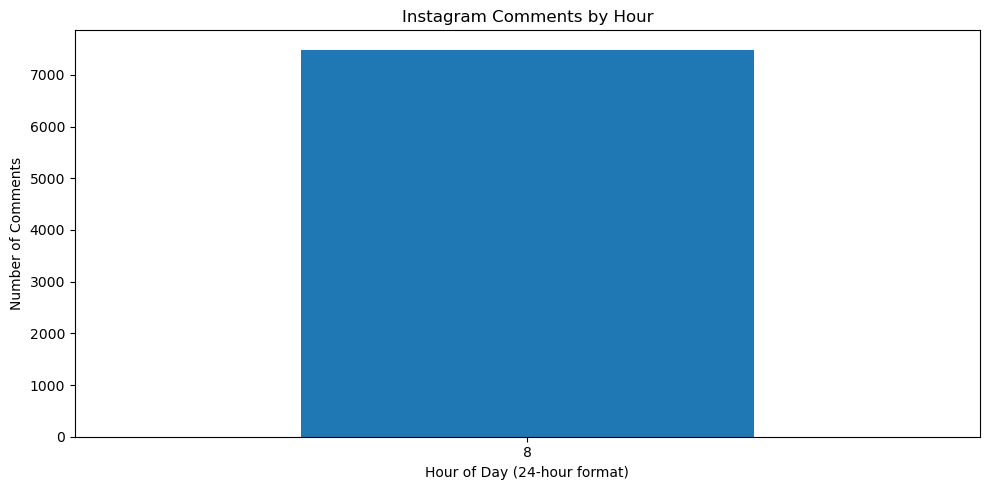

Hour with the most recorded comments: 8
Number of comments: 7488


In [3]:

# Count comments by hour
hourly_comments = df["comment_hour"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
hourly_comments.plot(kind="bar")
plt.title("Instagram Comments by Hour")
plt.xlabel("Hour of Day (24-hour format)")
plt.ylabel("Number of Comments")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Hour with the most recorded comments:",
      hourly_comments.idxmax())
print("Number of comments:",
      hourly_comments.max())


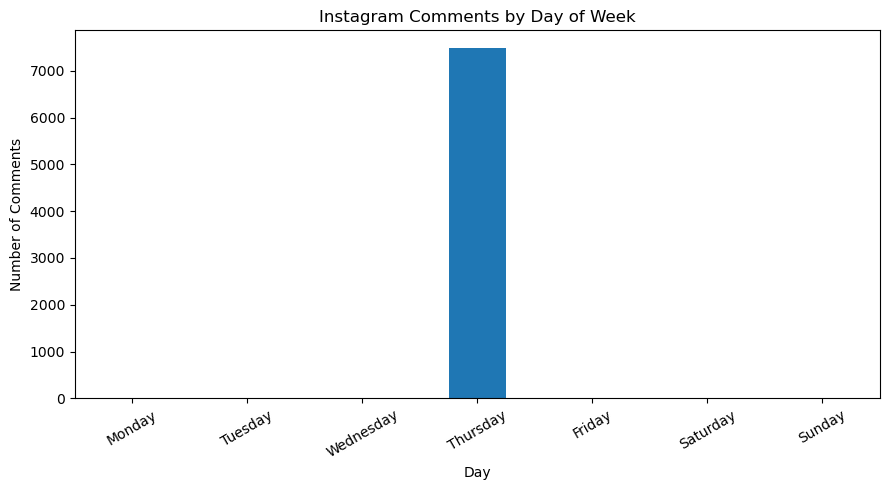

comment_day
Monday          NaN
Tuesday         NaN
Wednesday       NaN
Thursday     7488.0
Friday          NaN
Saturday        NaN
Sunday          NaN
Name: count, dtype: float64

In [4]:

daily_comments = df["comment_day"].value_counts().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday",
     "Friday", "Saturday", "Sunday"]
)

plt.figure(figsize=(9, 5))
daily_comments.plot(kind="bar")
plt.title("Instagram Comments by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Comments")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(daily_comments)


In [5]:

# Check the original dates and timestamps

print("Created Timestamp examples:")
print(df["created Timestamp"].head(10))

print("\nEarliest timestamp:")
print(df["created Timestamp"].min())

print("\nLatest timestamp:")
print(df["created Timestamp"].max())

print("\nOriginal posted dates:")
print(df["posted date"].value_counts().head(10))

print("\nNumber of unique posted dates:")
print(df["posted date"].nunique())


Created Timestamp examples:
0   2023-04-13 08:04:00
1   2023-04-13 08:04:00
2   2023-04-13 08:04:00
3   2023-04-13 08:04:00
4   2023-04-13 08:04:00
5   2023-04-13 08:04:00
6   2023-04-13 08:04:00
7   2023-04-13 08:04:00
8   2023-04-13 08:04:00
9   2023-04-13 08:04:00
Name: created Timestamp, dtype: datetime64[ns]

Earliest timestamp:
2023-04-13 08:04:00

Latest timestamp:
2023-04-13 08:04:00

Original posted dates:
posted date
April 14    7488
Name: count, dtype: int64

Number of unique posted dates:
1


Hashtag usage frequency:
Hashtags used count
0     624
1    1872
2    2496
3     624
4     624
5     624
6     624
Name: count, dtype: int64


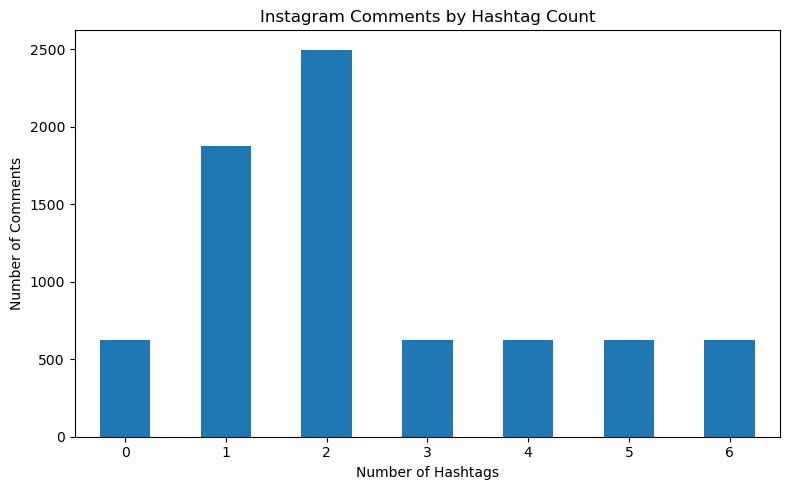

In [6]:

# Instagram hashtag analysis

hashtag_counts = df["Hashtags used count"].value_counts().sort_index()

print("Hashtag usage frequency:")
print(hashtag_counts)

plt.figure(figsize=(8, 5))
hashtag_counts.plot(kind="bar")
plt.title("Instagram Comments by Hashtag Count")
plt.xlabel("Number of Hashtags")
plt.ylabel("Number of Comments")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Emoji usage:
emoji used
yes    3744
no     3744
Name: count, dtype: int64


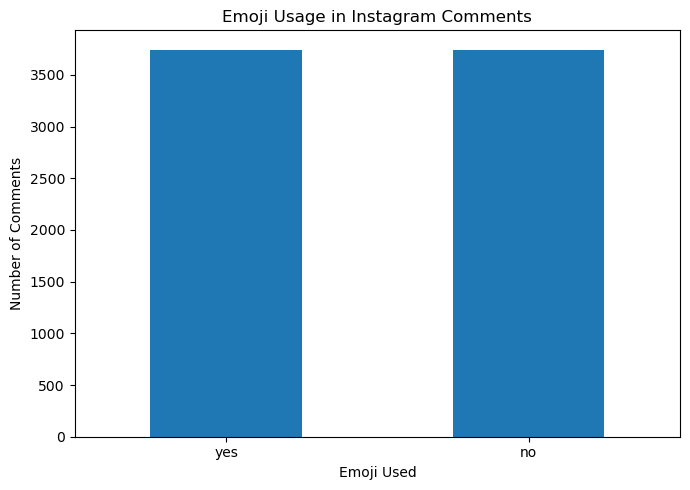

In [7]:

emoji_counts = df["emoji used"].value_counts()

print("Emoji usage:")
print(emoji_counts)

plt.figure(figsize=(7, 5))
emoji_counts.plot(kind="bar")
plt.title("Emoji Usage in Instagram Comments")
plt.xlabel("Emoji Used")
plt.ylabel("Number of Comments")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Top 10 commenters:
User id
75    257
36    257
76    257
71    257
66    257
57    257
91    257
41    257
54    257
24    257
Name: count, dtype: int64


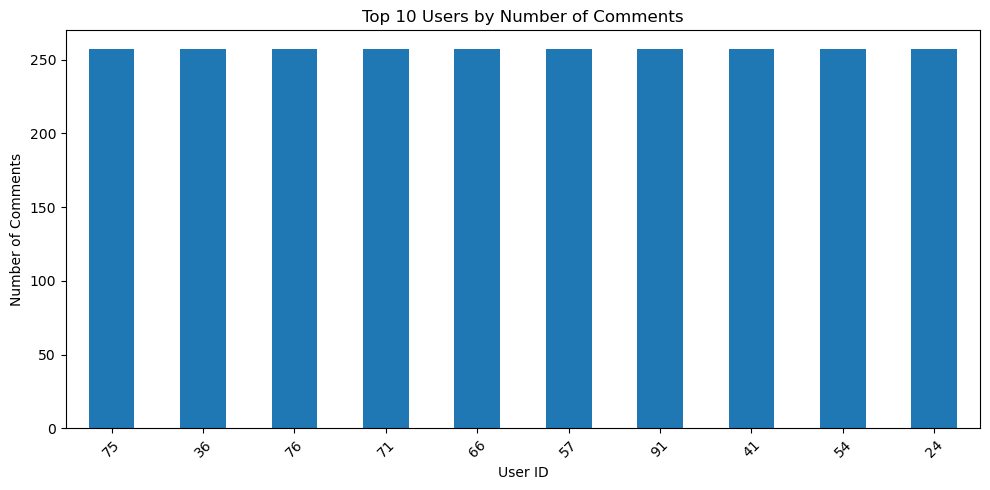

In [9]:


# Instagram: Top 10 Commenters

# Remove extra spaces from column names
df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace(r"\s+", " ", regex=True)

# Count comments by user
top_users = df["User id"].value_counts().head(10)

print("Top 10 commenters:")
print(top_users)

# Create chart
plt.figure(figsize=(10, 5))
top_users.plot(kind="bar")
plt.title("Top 10 Users by Number of Comments")
plt.xlabel("User ID")
plt.ylabel("Number of Comments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



Hashtag usage frequency:
Hashtags used count
0     624
1    1872
2    2496
3     624
4     624
5     624
6     624
Name: count, dtype: int64

Average hashtag count:
2.4166666666666665


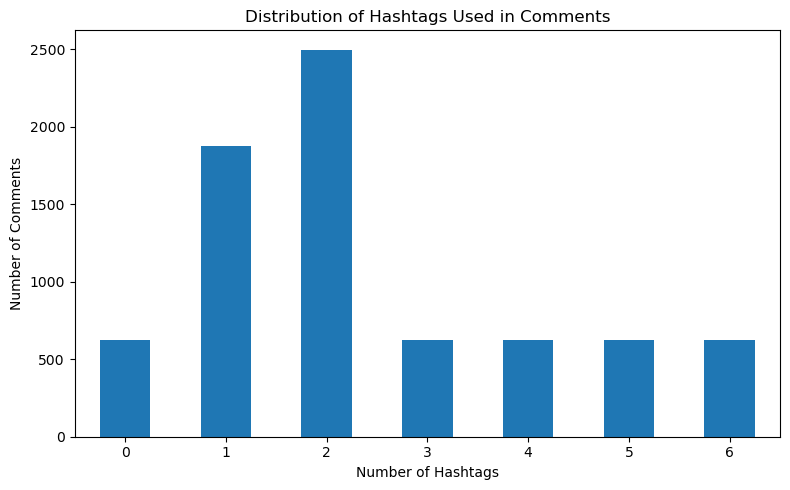

In [10]:

# Hashtag Usage Analysis

hashtag_counts = df["Hashtags used count"].value_counts().sort_index()

print("Hashtag usage frequency:")
print(hashtag_counts)

print("\nAverage hashtag count:")
print(df["Hashtags used count"].mean())

plt.figure(figsize=(8, 5))
hashtag_counts.plot(kind="bar")
plt.title("Distribution of Hashtags Used in Comments")
plt.xlabel("Number of Hashtags")
plt.ylabel("Number of Comments")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Emoji usage:
emoji used
yes    3744
no     3744
Name: count, dtype: int64


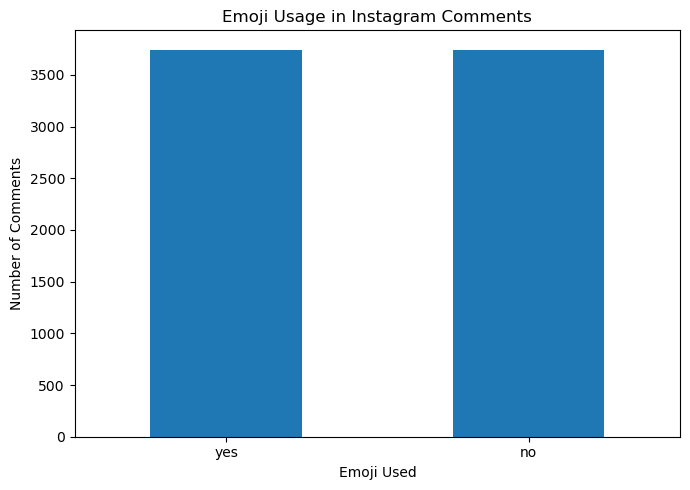

In [11]:

# Emoji Usage Analysis

emoji_counts = df["emoji used"].astype(str).str.lower().str.strip().value_counts()

print("Emoji usage:")
print(emoji_counts)

plt.figure(figsize=(7, 5))
emoji_counts.plot(kind="bar")
plt.title("Emoji Usage in Instagram Comments")
plt.xlabel("Emoji Used")
plt.ylabel("Number of Comments")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [12]:

# Instagram Data Analysis - Key Findings

print("===== INSTAGRAM DATA ANALYSIS =====")

print("\nTotal comments analyzed:", len(df))

print("\nAverage hashtags per comment:",
      round(df["Hashtags used count"].mean(), 2))

print("\nEmoji usage:")
print(df["emoji used"].value_counts())

print("\nMost common hashtag count:")
print(df["Hashtags used count"].mode().iloc[0])

print("\nUnique users:", df["User id"].nunique())
print("Unique photos:", df["Photo id"].nunique())


===== INSTAGRAM DATA ANALYSIS =====

Total comments analyzed: 7488

Average hashtags per comment: 2.42

Emoji usage:
emoji used
yes    3744
no     3744
Name: count, dtype: int64

Most common hashtag count:
2

Unique users: 77
Unique photos: 257


emoji used             no   yes
Hashtags used count            
0                       0   624
1                       0  1872
2                    1248  1248
3                     624     0
4                     624     0
5                     624     0
6                     624     0


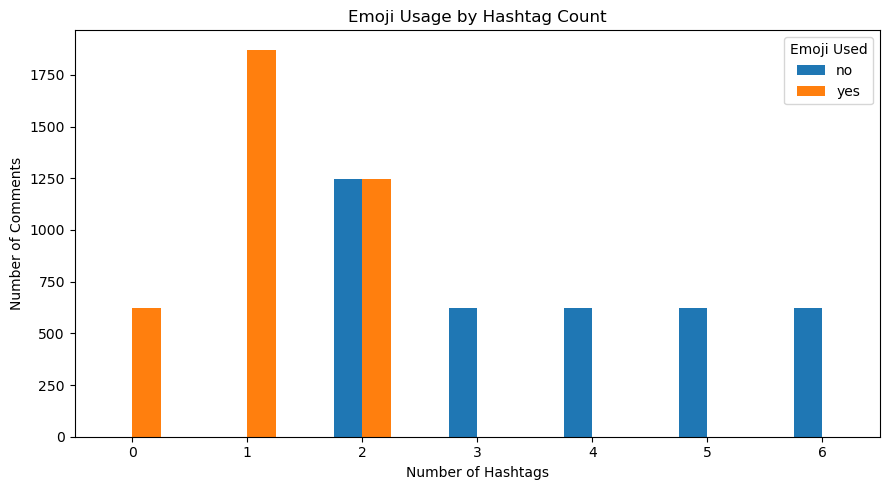

In [13]:

import pandas as pd
import matplotlib.pyplot as plt

# Compare emoji usage with hashtag counts
emoji_hashtag = pd.crosstab(
    df["Hashtags used count"],
    df["emoji used"]
)

print(emoji_hashtag)

emoji_hashtag.plot(kind="bar", figsize=(9, 5))
plt.title("Emoji Usage by Hashtag Count")
plt.xlabel("Number of Hashtags")
plt.ylabel("Number of Comments")
plt.xticks(rotation=0)
plt.legend(title="Emoji Used")
plt.tight_layout()
plt.savefig("chart3_emoji_hashtags.png", dpi=300)
plt.show()


In [14]:

# Check the number of unique timestamps and dates

print("Unique timestamps:",
      df["created Timestamp"].nunique())

print("\nMost common timestamps:")
print(df["created Timestamp"].value_counts().head(10))

print("\nUnique posted dates:",
      df["posted date"].nunique())

print("\nSample posted dates:")
print(df["posted date"].value_counts().head(10))


Unique timestamps: 1

Most common timestamps:
created Timestamp
2023-04-13 08:04:00    7488
Name: count, dtype: int64

Unique posted dates: 1

Sample posted dates:
posted date
April 14    7488
Name: count, dtype: int64


In [15]:

# Instagram comment analysis summary

total_comments = len(df)

emoji_percent = (
    df["emoji used"].astype(str).str.lower().eq("yes").mean() * 100
)

average_hashtags = df["Hashtags used count"].mean()

hashtag_distribution = (
    df["Hashtags used count"].value_counts().sort_index()
)

print("Total comments:", total_comments)
print(f"Comments using emojis: {emoji_percent:.2f}%")
print(f"Comments not using emojis: {100 - emoji_percent:.2f}%")
print(f"Average hashtags per comment: {average_hashtags:.2f}")

print("\nHashtag count distribution:")
print(hashtag_distribution)

# Save the summary for your project
summary = pd.DataFrame({
    "Metric": [
        "Total comments",
        "Emoji usage (%)",
        "No emoji usage (%)",
        "Average hashtags per comment"
    ],
    "Value": [
        total_comments,
        round(emoji_percent, 2),
        round(100 - emoji_percent, 2),
        round(average_hashtags, 2)
    ]
})

summary.to_csv("instagram_analysis_summary.csv", index=False)
print("\nSummary saved successfully.")


Total comments: 7488
Comments using emojis: 50.00%
Comments not using emojis: 50.00%
Average hashtags per comment: 2.42

Hashtag count distribution:
Hashtags used count
0     624
1    1872
2    2496
3     624
4     624
5     624
6     624
Name: count, dtype: int64

Summary saved successfully.


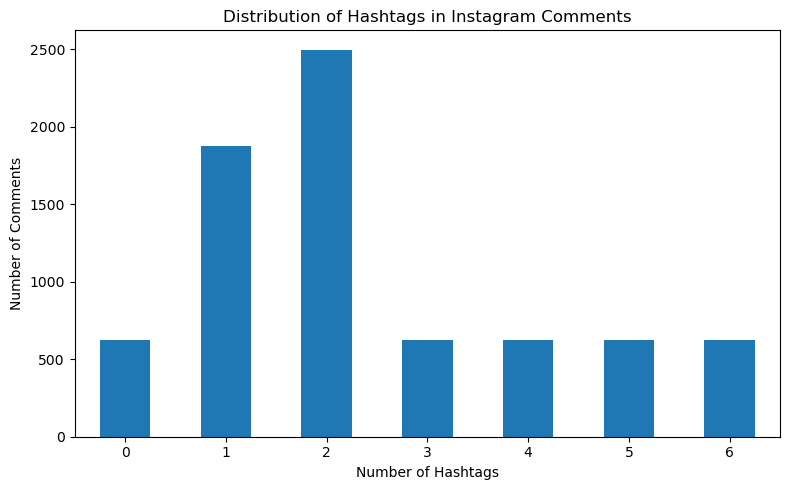

In [16]:

import matplotlib.pyplot as plt

hashtag_counts = df["Hashtags used count"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
hashtag_counts.plot(kind="bar")
plt.title("Distribution of Hashtags in Instagram Comments")
plt.xlabel("Number of Hashtags")
plt.ylabel("Number of Comments")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("chart4_hashtag_distribution.png", dpi=300)
plt.show()


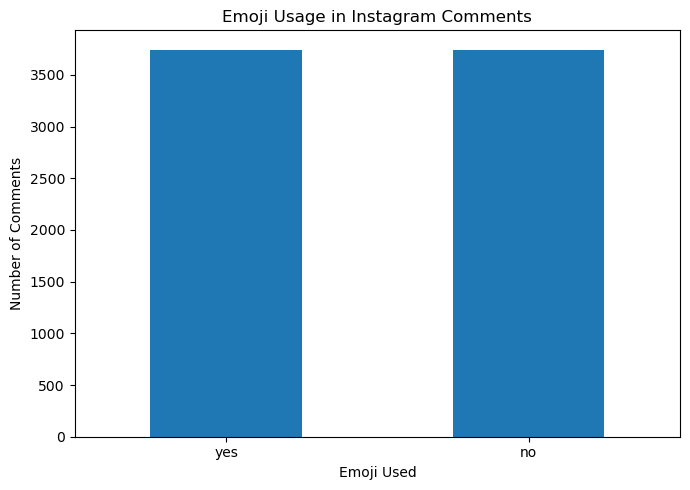

In [17]:

emoji_counts = df["emoji used"].astype(str).str.lower().value_counts()

plt.figure(figsize=(7, 5))
emoji_counts.plot(kind="bar")
plt.title("Emoji Usage in Instagram Comments")
plt.xlabel("Emoji Used")
plt.ylabel("Number of Comments")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("chart5_emoji_usage.png", dpi=300)
plt.show()
